In [2]:
import numpy as np
import scipy as sc
import matplotlib.pyplot as plt

In [3]:
# constants
a = 0.2
b = 0.2
c = 5.7

# rossler attractor
def rossler(t, state):
    x = state[0]
    y = state[1]
    z = state[2]
    dx_dt = -y - z
    dy_dt = x + a*y 
    dz_dt = b + z*(x - c)
    return dx_dt, dy_dt, dz_dt

Text(0.5, 0, '$z$')

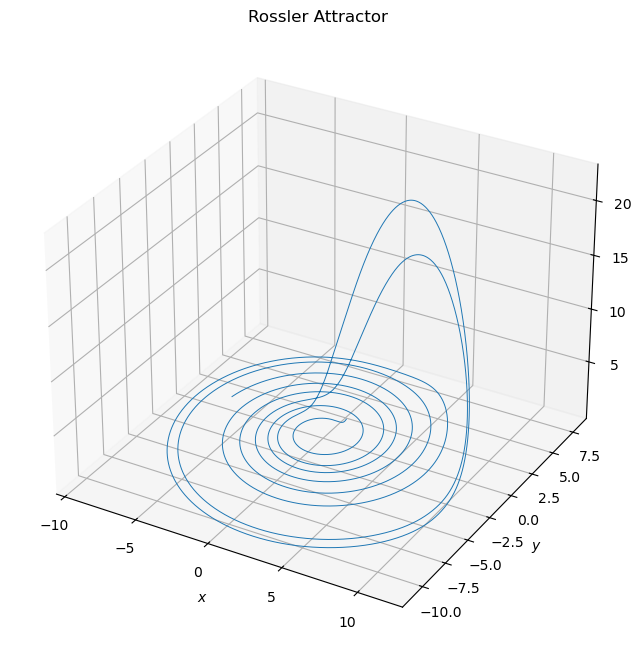

In [ ]:
# part a - plot
t_start = 0
t_end = 50
t_vals = np.linspace(t_start, t_end, 20000)

x0 = [1, 1, 1]

sol = sc.integrate.solve_ivp(rossler, [t_start, t_end], x0, t_eval=t_vals)

# dont need to cut off any because IC so close to attractor
trans_cutoff = 0
mask = sol.t >= trans_cutoff
t_steady = sol.t[mask]
x = sol.y[0][mask]
y = sol.y[1][mask]
z = sol.y[2][mask]

fig = plt.figure(figsize=(20,8))
ax = fig.add_subplot(projection='3d')
ax.plot(x, y, z, lw=0.7)
ax.set_title('Rossler Attractor')
ax.set_xlabel('$x$')
ax.set_ylabel('$y$')
ax.set_zlabel("$z$")

In [5]:
# part b - find intersections (x_n,z_n) and (x_n, x_{n+1})
t_start = 0
t_end = 2000 # to make sure we get 200 pts
t_vals = np.linspace(t_start, t_end, 20000)
x0 = [1,1,1]

sol = sc.integrate.solve_ivp(rossler, [t_start, t_end], x0, t_eval=t_vals)
trans_cutoff = 10
mask = sol.t >= trans_cutoff
t_steady = sol.t[mask]
x = sol.y[0][mask]
y = sol.y[1][mask]
z = sol.y[2][mask]

# to confirm via plotting that we have entered the attractor
# fig = plt.figure(figsize=(20,8))
# ax = fig.add_subplot(projection='3d')
# ax.plot(x, y, z, lw=0.7)
# ax.set_title('Rossler Attractor')
# ax.set_xlabel('$x$')
# ax.set_ylabel('$y$')
# ax.set_zlabel("$z$")

x_cross = []
z_cross = []

for i in range(len(y)-1):
    # first check if we pass over zero and x < 0
    if y[i] >= 0 and y[i+1] <= 0 and x[i] < 0:
        # do a linear interpolation to try and approximate where y=0
        m = -y[i]/(y[i+1] - y[i])
        x_c = x[i] + m*(x[i+1]-x[i])
        z_c = z[i] + m*(z[i+1]-z[i])
        x_cross.append(x_c)
        z_cross.append(z_c)

print(f'Total crossings = {len(x_cross)}')

x_old = x_cross[:-1]
x_new = x_cross[1:]

Total crossings = 340


Text(0.5, 1.0, 'Poincare Map')

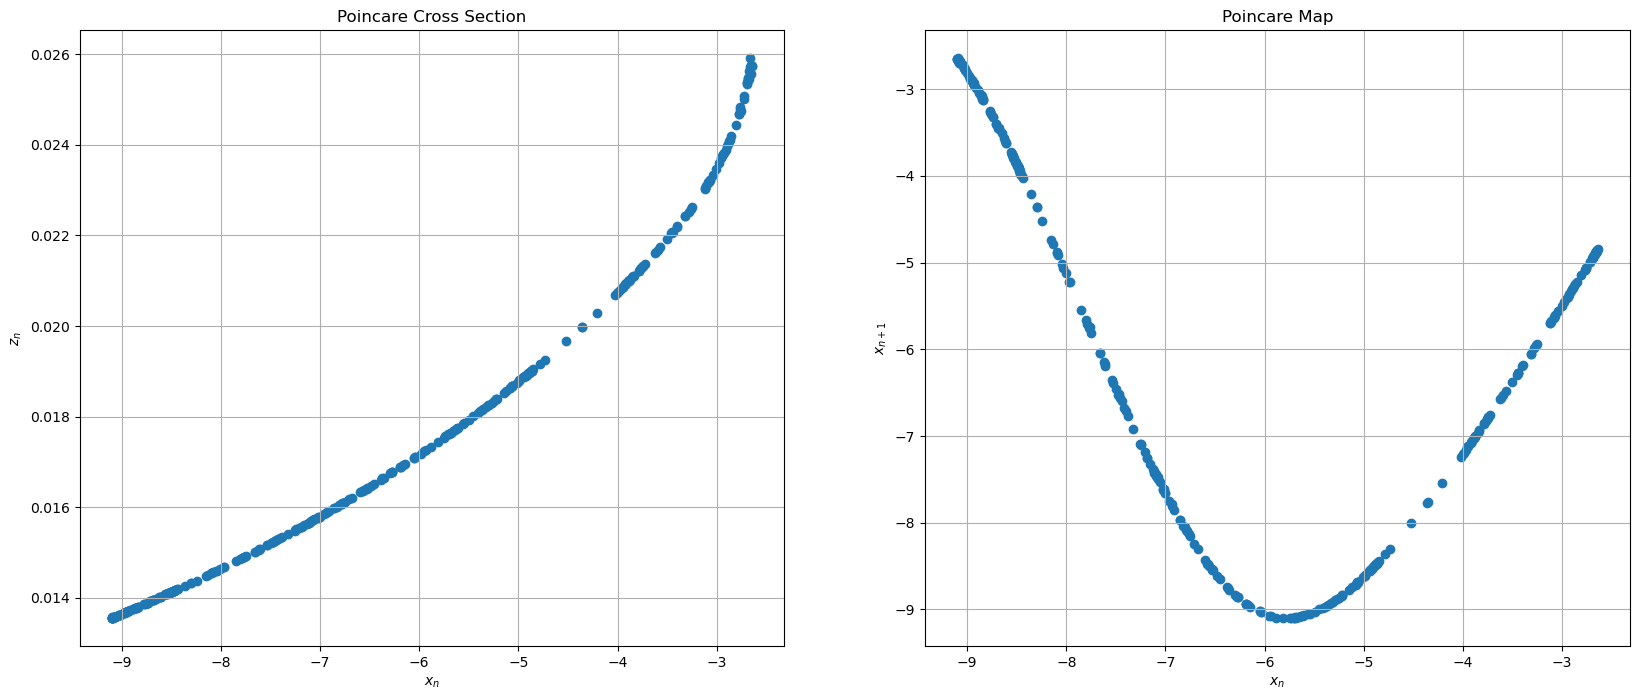

In [6]:
# part c - plotting
fig, axs = plt.subplots(1,2, figsize=(20,8))
axs[0].grid(True)
axs[0].scatter(x_cross, z_cross)
axs[0].set_xlabel('$x_n$')
axs[0].set_ylabel('$z_n$')
axs[0].set_title('Poincare Cross Section')

axs[1].grid(True)
axs[1].scatter(x_old, x_new)
axs[1].set_xlabel('$x_n$')
axs[1].set_ylabel('$x_{n+1}$')
axs[1].set_title('Poincare Map')

In [7]:
# part d - construct approximating polynomials
degree = 10
q_coeffs = np.polyfit(x_cross, z_cross, degree)
p_coeffs = np.polyfit(x_old, x_new, degree)

x_fit = np.linspace(-10, 4, 10000)
q_fit = np.polyval(q_coeffs, x_fit)
p_fit = np.polyval(p_coeffs, x_fit)

print(f'Q(x_n) coefficients: {q_coeffs}')
print(f'P(x_n) coefficients: {p_coeffs}')


Q(x_n) coefficients: [5.56866120e-08 3.44098457e-06 9.44481300e-05 1.51562592e-03
 1.57387020e-02 1.10457789e-01 5.30398753e-01 1.72022294e+00
 3.60637385e+00 4.41711693e+00 2.42836586e+00]
P(x_n) coefficients: [1.65546815e-05 1.00407418e-03 2.67827953e-02 4.12975717e-01
 4.06991058e+00 2.67579697e+01 1.18819270e+02 3.51952527e+02
 6.65933626e+02 7.29226274e+02 3.48610864e+02]


In [26]:
# part e - find periodic orbits

# set up the functions and iterations
def P(x):
    return np.polyval(p_coeffs, x)

def Q(x):
    return np.polyval(q_coeffs, x)

def P_k(x, k):
    val = x
    for _ in range(k):
        val = P(val)
    return val

#  do the actual root finding

x_vals = np.linspace(-11, -2, 3000)

def find_roots(k):
    f = lambda x: P_k(x,k) - x
    f_vals = f(x_vals)
    roots = []

    for i in range(len(x_vals) - 1):
        if f_vals[i] * f_vals[i+1] <=0:
            try:
                root = sc.optimize.bisect(f, x_vals[i], x_vals[i+1])
                if not any(np.isclose(root, r, atol=1e-4) for r in roots):
                    roots.append(root)
            except ValueError:
                continue

    return np.array(sorted(roots))

roots1 = find_roots(1)
roots2 = find_roots(2)
roots3 = find_roots(3)
#print(roots1)
#print(roots2)
#print(roots3)

print(f'{roots1[0]} -> {P(roots1[0])}')
print(f'{roots2[0]} -> {P(roots2[0])} -> {P(roots2[2])}')
print(f'{roots3[0]} -> {P(roots3[0])} -> {P(roots3[6])} -> {P(roots3[4])}')
print(f'{roots3[1]} -> {P(roots3[1])} -> {P(roots3[5])} -> {P(roots3[3])}')


-7.202110563389486 -> -7.202110563402982
-8.184766646019185 -> -4.653261165457536 -> -8.184766646018659
-8.940061150939323 -> -2.9216778492640287 -> -5.347946748359732 -> -8.940061150957092
-8.633874218081314 -> -3.556013598268578 -> -6.461131766866231 -> -8.633874218051119


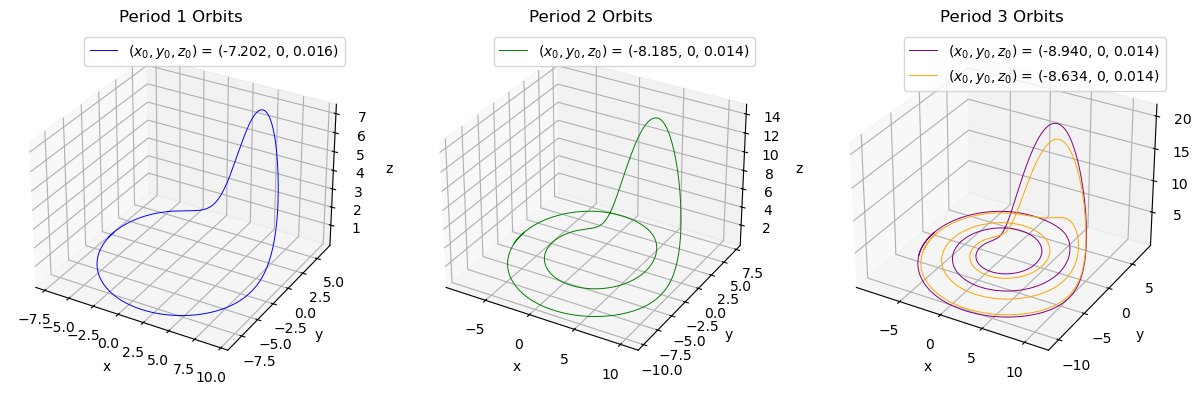

In [52]:
# part f
x01 = [roots1[0], 0, Q(roots1[0])]
x02 = [roots2[0], 0, Q(roots2[0])]
x03a = [roots3[0], 0, Q(roots3[0])]
x03b = [roots3[1], 0, Q(roots3[1])]

t_vals1 = np.linspace(0, 6, 2000)
t_vals2 = np.linspace(0, 12, 2000)
t_vals3a = np.linspace(0, 18, 2000)
t_vals3b = np.linspace(0, 18, 2000)

sol1 = sc.integrate.solve_ivp(rossler, [0, 6], x01, t_eval=t_vals1)
sol2 = sc.integrate.solve_ivp(rossler, [0, 12], x02, t_eval=t_vals2)
sol3a = sc.integrate.solve_ivp(rossler, [0, 18], x03a, t_eval=t_vals3a)
sol3b = sc.integrate.solve_ivp(rossler, [0, 18], x03b, t_eval=t_vals3b)

fig = plt.figure(figsize=(15,6))
ax1 = fig.add_subplot(1, 3, 1, projection='3d')
ax1.plot(sol1.y[0], sol1.y[1], sol1.y[2], lw=0.7, label=f'($x_0, y_0, z_0$) = ({x01[0]:.3f}, 0, {x01[2]:.3f})', color='blue')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_zlabel('z')
ax1.set_title('Period 1 Orbits')
ax1.legend()

ax2 = fig.add_subplot(1, 3, 2, projection='3d')
ax2.plot(sol2.y[0], sol2.y[1], sol2.y[2], lw=0.7, label=f'($x_0, y_0, z_0$) = ({x02[0]:.3f}, 0, {x02[2]:.3f})', color='green')
ax2.set_xlabel('x')
ax2.set_ylabel('y')
ax2.set_zlabel('z')
ax2.set_title('Period 2 Orbits')
ax2.legend()

ax3 = fig.add_subplot(1, 3, 3, projection='3d')
ax3.plot(sol3a.y[0], sol3a.y[1], sol3a.y[2], lw=0.7, label=f'($x_0, y_0, z_0$) = ({x03a[0]:.3f}, 0, {x03a[2]:.3f})', color='purple')
ax3.plot(sol3b.y[0], sol3b.y[1], sol3b.y[2], lw=0.7, label=f'($x_0, y_0, z_0$) = ({x03b[0]:.3f}, 0, {x03b[2]:.3f})', color='orange')
ax3.set_xlabel('x')
ax3.set_ylabel('y')
ax3.set_zlabel('z')
ax3.set_title('Period 3 Orbits')
ax3.legend()
